In [10]:
import matplotlib.pyplot as plt
import sys
sys.path.append('../scripts')
from utils.cftp_func import *

# Test forward bounding chain (one run)

In [2]:
N = 500
d = 4
beta = 0.26
maxiter = 100000
G, couplings = create_ER_graph(N, d, coupling_type='ising')
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(0.25541281188299536, 0.5493061443340549)

In [3]:
nb_star_state, final_step = BC_fwd(beta, G, couplings, sampler=F_beta_Glauber, max_iter=maxiter, init_mode='full_star', lazy=False)

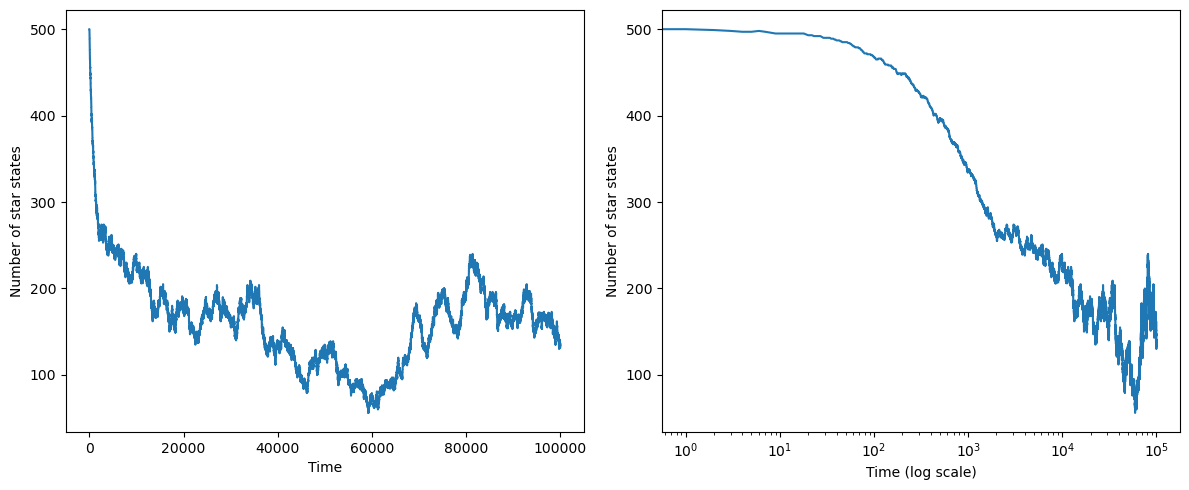

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_star_state)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of star states')

ax2.plot(nb_star_state)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of star states')

plt.tight_layout()
plt.show()

# Coalescence times

In [11]:
N_list = [100, 200, 300]
beta = 0.2
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type='gauss')
df = compute_coal_time(N_list, beta, G_builder, n_runs=4, sampler=F_beta_Glauber, max_iter=50000, init_mode='full_star', lazy=False)

Coalescence achieved at iteration 1146 using full_star initialization.
Coalescence achieved at iteration 1113 using full_star initialization.
Coalescence achieved at iteration 1980 using full_star initialization.
Coalescence achieved at iteration 1069 using full_star initialization.
Coalescence achieved at iteration 2519 using full_star initialization.
Coalescence achieved at iteration 2470 using full_star initialization.
Coalescence achieved at iteration 6170 using full_star initialization.
Coalescence achieved at iteration 2902 using full_star initialization.
Coalescence achieved at iteration 6814 using full_star initialization.
Coalescence achieved at iteration 7108 using full_star initialization.
Coalescence achieved at iteration 5674 using full_star initialization.
Coalescence achieved at iteration 5692 using full_star initialization.


In [12]:
# ADD sampler, coupling_type, nb trials, nb iters, graph type, init model lazy
df.to_csv('../results/tmp/coal_time_ER_beta0.3.csv', index=False)

In [17]:
df['beta'] == beta

0    True
1    True
2    True
Name: beta, dtype: bool

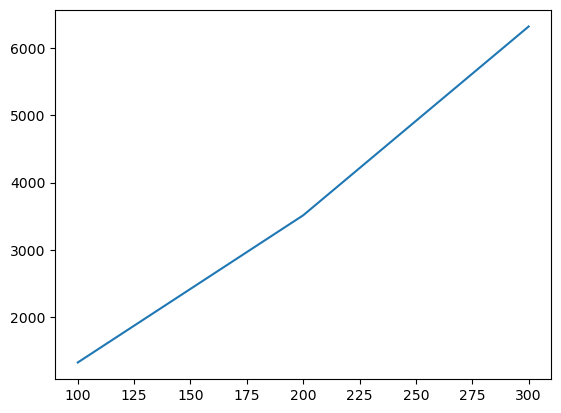

In [ ]:
for beta in df['beta'].unique(): # for all distincts values of beta in df
    sub_df = df[df['beta'] == beta] # subset of df with beta
    plt.plot(sub_df['N'], sub_df['mean_coal_time'], label=f'beta={beta}')